# Text Classification with BiLSTM and Attention for Symptom-Disease Prediction

## Project overview

This notebook builds a neural text classifier that maps a free-text symptom description to a disease label. The workflow cleans the text, encodes labels, creates a vocabulary, initializes word embeddings from GloVe, trains a bidirectional LSTM with attention, and evaluates the predictions with classification metrics and a confusion matrix.

The notebook is organized as an end-to-end experiment. Run the cells from top to bottom so that each later section can use the data, vocabulary, model, and training history created earlier.

## 1. Imports and runtime device

The first code cell imports the data-science and deep-learning libraries. The following cell selects CUDA when it is available and otherwise uses the CPU.

In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [70]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## 2. Load and inspect the dataset

The CSV contains symptom descriptions in `text` and their target disease names in `label`. The inspection cells check the sample rows, dataset size, and class distribution before preprocessing.

In [ ]:
df = pd.read_csv('Symptom2Disease.csv')

In [72]:
df.head()

,Unnamed: 0,label,text
0,0,Psoriasis,I have been experiencing a skin rash on my arm...
1,1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,2,Psoriasis,I have been experiencing joint pain in my fing...
3,3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,4,Psoriasis,"My nails have small dents or pits in them, and..."


In [73]:
len(df)

1200

In [74]:
df['label'].value_counts()

,count
label,
Psoriasis,50
Varicose Veins,50
Typhoid,50
Chicken pox,50
Impetigo,50
Dengue,50
Fungal infection,50
Common Cold,50
Pneumonia,50


In [132]:
nltk.download('stopwords')
nltk.download('wordnet')

stopwords = set(nltk.corpus.stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## 3. Text preprocessing

Each description is normalized to lowercase, URLs and punctuation are removed, stop words are filtered, and words are lemmatized. The cleaned text is used for both vocabulary construction and model input.

In [ ]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    tokens = []
    for word in text.split():
        if word not in stopwords:
            tokens.append(lemmatizer.lemmatize(word))
    return ' '.join(tokens)

In [ ]:
print(f"The original text: {df['text'][0]}")
print(f"Cleaned text: {preprocess_text(df['text'][0])}")

The original text: I have been experiencing a skin rash on my arms, legs, and torso for the past few weeks. It is red, itchy, and covered in dry, scaly patches.
Cleaned text: experiencing skin rash arm leg torso past week red itchy covered dry scaly patch


In [ ]:
df['cleaned_text'] = df['text'].apply(preprocess_text)

## 4. Encode labels and split the data

Disease names are converted to integer class IDs. A stratified split keeps the class proportions similar in the training and test sets.

In [ ]:
label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['label'])
num_classes = len(label_encoder.classes_)

In [ ]:
num_classes

24

In [ ]:
label_encoder.classes_

array(['Acne', 'Arthritis', 'Bronchial Asthma', 'Cervical spondylosis',
       'Chicken pox', 'Common Cold', 'Dengue', 'Dimorphic Hemorrhoids',
       'Fungal infection', 'Hypertension', 'Impetigo', 'Jaundice',
       'Malaria', 'Migraine', 'Pneumonia', 'Psoriasis', 'Typhoid',
       'Varicose Veins', 'allergy', 'diabetes', 'drug reaction',
       'gastroesophageal reflux disease', 'peptic ulcer disease',
       'urinary tract infection'], dtype=object)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
        df['cleaned_text'].values,
        df['label_encoded'].values,
        test_size=0.2,
        shuffle=True,
        random_state=42,
        stratify=df['label_encoded'].values
    )

## 5. Build the vocabulary and GloVe matrix

The vocabulary is learned from training text only. GloVe vectors initialize known words, while the padding token receives zeros and unknown words receive randomly initialized vectors.

In [ ]:
class Vocabulary:
    def __init__(self, pad_token="<PAD>", unk_token="<UNK>"):
        self.pad_token = pad_token
        self.unk_token = unk_token
        self.word2idx = {pad_token: 0, unk_token: 1}
        self.idx2word = {0: pad_token, 1: unk_token}
        self.idx = 2

    def build_vocab(self, sentence_list):
        for sentence in sentence_list:
            for word in sentence.split():
                if word not in self.word2idx:
                    self.word2idx[word] = self.idx
                    self.idx2word[self.idx] = word
                    self.idx += 1

    def numericalize(self, text):
        return [self.word2idx.get(word, self.word2idx[self.unk_token]) for word in text.split()]

    def __len__(self):
        return len(self.word2idx)

In [ ]:
vocab = Vocabulary()
vocab.build_vocab(X_train)
print(f"Vocab size: {len(vocab)}")

Vocab size: 1278


In [ ]:
vocab.numericalize(X_train[0])

[2, 3, 4, 5, 6, 2, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

In [ ]:
max_len = 0
for text in df['cleaned_text']:
  max_len = max(max_len, len(text.split()))
print(max_len)

30


In [ ]:
def load_glove_embeddings(glove_file_path, vocab, embedding_dim=100):
    embeddings_index = {}
    print("Loading GloVe Embeddings...")
    with open(glove_file_path, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            vector = np.asarray(values[1:], dtype='float32')
            embeddings_index[word] = vector

    matrix_len = len(vocab)
    weights_matrix = np.zeros((matrix_len, embedding_dim))

    for word, i in vocab.word2idx.items():
        if word == vocab.pad_token:
            weights_matrix[i] = np.zeros(embedding_dim)
        elif word in embeddings_index:
            weights_matrix[i] = embeddings_index[word]
        else:
            weights_matrix[i] = np.random.normal(scale=0.6, size=(embedding_dim,))

    return torch.tensor(weights_matrix, dtype=torch.float32)

In [ ]:
pretrained_weights = load_glove_embeddings('glove.6B.100d.txt', vocab, 100)

Loading GloVe Embeddings...


In [ ]:
pretrained_weights[0]

tensor([ 2.7963e-02, -4.5440e-02, -2.1906e-02,  8.2532e-02,  5.3714e-02,
        -3.0288e-02,  5.1367e-02, -4.8474e-02, -3.7839e-02, -1.2075e-03,
         7.9662e-02,  8.1118e-03, -7.9938e-02, -4.1572e-02, -7.6059e-02,
         8.7586e-06,  2.7804e-02,  1.5946e-02, -4.4482e-02,  3.0211e-02,
         1.1739e-02, -2.5712e-02,  3.7964e-02,  4.0562e-02, -7.3716e-02,
        -1.1324e-01,  2.9981e-02,  1.0431e-01, -7.6372e-02,  3.7093e-02,
        -7.4606e-02, -8.2462e-02, -2.7489e-02,  1.1389e-01, -6.6522e-03,
        -4.2545e-02, -9.7697e-03,  4.9474e-03, -5.2020e-02, -5.6318e-02,
        -2.1483e-02,  4.4401e-02,  2.6300e-02,  3.6616e-02,  9.1737e-02,
        -3.6424e-02, -8.3182e-02, -5.4637e-02,  1.7077e-02,  8.4682e-02,
        -4.9355e-02,  5.4484e-02,  7.3593e-02, -1.5760e-01,  1.9391e-02,
         1.4526e-01, -4.6218e-02,  6.5022e-03, -9.3877e-02, -4.9568e-02,
        -4.4262e-02, -1.2387e-01,  1.0713e-01, -8.2099e-02, -5.7469e-02,
        -2.9235e-02, -8.3793e-02,  1.1280e-02, -2.7

In [ ]:
class SymptomDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_len=50):
        self.texts = texts
        self.labels = labels
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        text = self.texts[index]
        label = self.labels[index]

        numericalized = self.vocab.numericalize(text)

        if len(numericalized) < self.max_len:
            padded = numericalized + [self.vocab.word2idx[self.vocab.pad_token]] * (self.max_len - len(numericalized))
        else:
            padded = numericalized[:self.max_len]

        return torch.tensor(padded, dtype=torch.long), torch.tensor(label, dtype=torch.long)

In [ ]:
train_dataset = SymptomDataset(X_train, y_train, vocab, max_len=max_len)
test_dataset = SymptomDataset(X_test, y_test, vocab, max_len=max_len)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## 6. Attention, and BiLSTM model

The bidirectional LSTM reads context in both directions, and the attention layer learns which sequence positions contribute most to the final disease prediction.

In [ ]:
class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super(Attention, self).__init__()
        self.projection = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, lstm_outputs):
        # lstm_outputs shape: (batch_size, seq_len, hidden_dim)
        u = torch.tanh(self.projection(lstm_outputs))         # (batch_size, seq_len, hidden_dim)
        scores = self.v(u).squeeze(-1)                         # (batch_size, seq_len)
        weights = F.softmax(scores, dim=1)                    # (batch_size, seq_len)

        # M = sum(alpha_t * h_t)
        context = torch.bmm(weights.unsqueeze(1), lstm_outputs).squeeze(1) # (batch_size, hidden_dim)
        return context, weights

In [ ]:
class BiLSTM_Attention_Classifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, num_layers=1, pretrained_embeddings=None, dropout=0.3):
        super(BiLSTM_Attention_Classifier, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        if pretrained_embeddings is not None:
            self.embedding.weight = nn.Parameter(pretrained_embeddings)
            self.embedding.weight.requires_grad = True

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            num_layers=num_layers,
            bidirectional=True,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.attention = Attention(hidden_dim * 2)
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        # x: (batch_size, seq_len)
        embedded = self.embedding(x)                             # (batch_size, seq_len, embedding_dim)
        lstm_out, _ = self.lstm(embedded)                        # (batch_size, seq_len, hidden_dim * 2)
        context, attn_weights = self.attention(lstm_out)         # context: (batch_size, hidden_dim * 2)
        logits = self.fc(context)                                # (batch_size, output_dim)

        return logits, attn_weights

In [ ]:
model = BiLSTM_Attention_Classifier(
    vocab_size=len(vocab),
    embedding_dim=100,
    hidden_dim=128,
    output_dim=num_classes,
    pretrained_embeddings=pretrained_weights,
    dropout=0.3

    ).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

## 7. Train with early stopping

The classifier is optimized with AdamW and cross-entropy loss. Weighted F1, precision, and recall are tracked for both splits, and the best test F1 checkpoint is saved as `best_model.pt`.

In [ ]:
def score(y_true_list, y_pred_logits_list):
    y_true_np = np.array(y_true_list)
    y_pred_logits_np = np.array(y_pred_logits_list)

    y_pred_np = np.argmax(y_pred_logits_np, axis=1)

    f1 = f1_score(y_true_np, y_pred_np, average='weighted', zero_division=0)
    precision = precision_score(y_true_np, y_pred_np, average='weighted', zero_division=0)
    recall = recall_score(y_true_np, y_pred_np, average='weighted', zero_division=0)

    return f1, precision, recall

In [ ]:
def train(model, DataLoader, optimizer, criterion, metric, device):
    model.train()

    all_labels = []
    all_logits = []
    epoch_loss = 0

    for text, label in DataLoader:
      text = text.to(device)
      label = label.to(device)

      optimizer.zero_grad()
      logits, _ = model(text)
      loss = criterion(logits, label)
      loss.backward()
      optimizer.step()

      epoch_loss += loss.item()
      all_labels.extend(label.cpu().numpy())
      all_logits.extend(logits.cpu().detach().numpy())

    f1, precision, recall = metric(all_labels, all_logits)
    return epoch_loss / len(DataLoader), f1, precision, recall

In [ ]:
def evaluate(model, DataLoader, criterion, metric, device):
    model.eval()

    all_labels = []
    all_logits = []
    epoch_loss = 0

    with torch.no_grad():
        for text, label in DataLoader:
            text = text.to(device)
            label = label.to(device)

            logits, _ = model(text)
            loss = criterion(logits, label)

            epoch_loss += loss.item()
            all_labels.extend(label.cpu().numpy())
            all_logits.extend(logits.cpu().detach().numpy())

    f1, precision, recall = metric(all_labels, all_logits)
    return epoch_loss / len(DataLoader), f1, precision, recall

In [ ]:
def fit(epochs, model, train_loader, test_loader, criterion, optimizer, metric, device, patience):
    best_f1 = 0
    patience_counter = 0

    train_losses_history = []
    train_f1s_history = []
    train_precisions_history = []
    train_recalls_history = []

    test_losses_history = []
    test_f1s_history = []
    test_precisions_history = []
    test_recalls_history = []

    for epoch in range(epochs):
        current_train_loss, current_train_f1, current_train_precision, current_train_recall = train(model, train_loader, optimizer, criterion, metric, device)
        current_test_loss, current_test_f1, current_test_precision, current_test_recall = evaluate(model, test_loader, criterion, metric, device)

        print(f'Epoch: {epoch+1}/{epochs} | train_loss:{current_train_loss:.2f} | train_f1:{current_train_f1:.2f} | test_loss:{current_test_loss:.2f} | test_f1:{current_test_f1:.2f}\n')

        train_losses_history.append(current_train_loss)
        train_f1s_history.append(current_train_f1)
        train_precisions_history.append(current_train_precision)
        train_recalls_history.append(current_train_recall)

        test_losses_history.append(current_test_loss)
        test_f1s_history.append(current_test_f1)
        test_precisions_history.append(current_test_precision)
        test_recalls_history.append(current_test_recall)

        if current_test_f1 > best_f1:
            best_f1 = current_test_f1
            torch.save(model.state_dict(), 'best_model.pt')
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f'Early stopping at epoch {epoch+1}')
                break

    return train_losses_history, train_f1s_history, train_precisions_history, train_recalls_history, test_losses_history, test_f1s_history, test_precisions_history, test_recalls_history

In [ ]:
train_losses, train_f1s, train_precisions, train_recalls, test_losses, test_f1s, test_precisions, test_recalls = fit(100, model, train_loader, test_loader, criterion, optimizer, score, device, 10)

Epoch: 1/100 | train_loss:3.10 | train_f1:0.10 | test_loss:2.81 | test_f1:0.22

Epoch: 2/100 | train_loss:2.01 | train_f1:0.44 | test_loss:1.21 | test_f1:0.69

Epoch: 3/100 | train_loss:0.87 | train_f1:0.79 | test_loss:0.62 | test_f1:0.84

Epoch: 4/100 | train_loss:0.38 | train_f1:0.92 | test_loss:0.42 | test_f1:0.87

Epoch: 5/100 | train_loss:0.23 | train_f1:0.96 | test_loss:0.29 | test_f1:0.90

Epoch: 6/100 | train_loss:0.16 | train_f1:0.97 | test_loss:0.35 | test_f1:0.88

Epoch: 7/100 | train_loss:0.08 | train_f1:0.99 | test_loss:0.24 | test_f1:0.92

Epoch: 8/100 | train_loss:0.05 | train_f1:0.99 | test_loss:0.21 | test_f1:0.92

Epoch: 9/100 | train_loss:0.04 | train_f1:1.00 | test_loss:0.19 | test_f1:0.92

Epoch: 10/100 | train_loss:0.03 | train_f1:1.00 | test_loss:0.21 | test_f1:0.92

Epoch: 11/100 | train_loss:0.02 | train_f1:1.00 | test_loss:0.19 | test_f1:0.93

Epoch: 12/100 | train_loss:0.01 | train_f1:1.00 | test_loss:0.18 | test_f1:0.92

Epoch: 13/100 | train_loss:0.01 | tra

## 8. Evaluate and inspect attention

The final cells print a per-class classification report, display a confusion matrix, and provide a helper for predicting a new symptom description while visualizing the words that received the greatest attention.

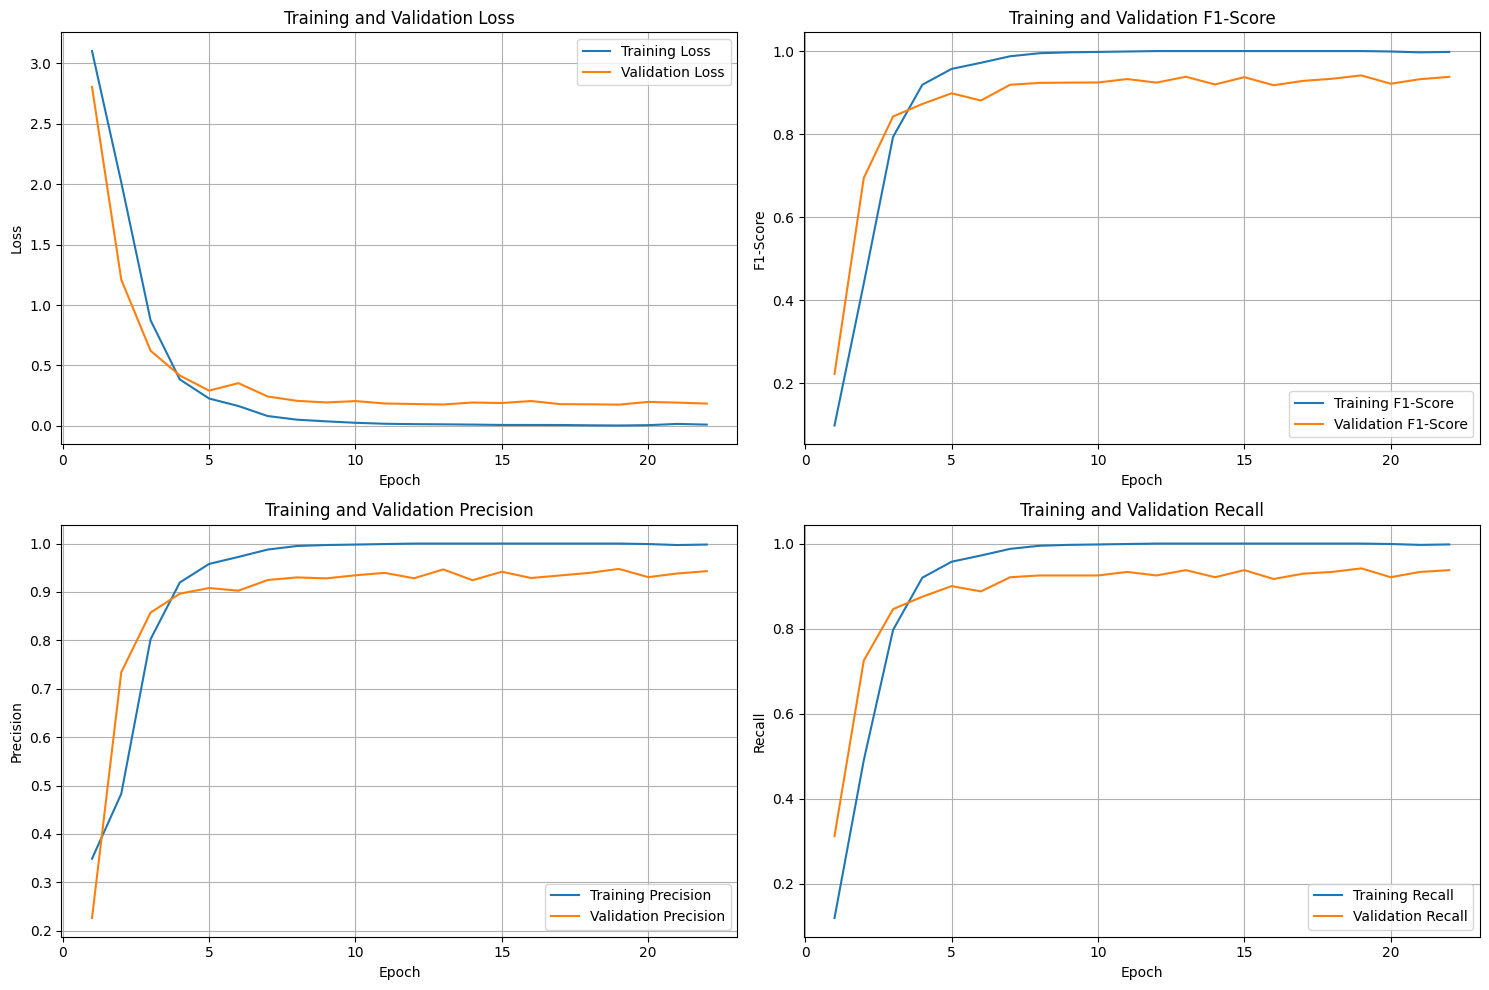

In [ ]:
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(15, 10))

# Plotting Loss
plt.subplot(2, 2, 1)
plt.plot(epochs_range, train_losses, label='Training Loss')
plt.plot(epochs_range, test_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plotting F1 Score
plt.subplot(2, 2, 2)
plt.plot(epochs_range, train_f1s, label='Training F1-Score')
plt.plot(epochs_range, test_f1s, label='Validation F1-Score')
plt.title('Training and Validation F1-Score')
plt.xlabel('Epoch')
plt.ylabel('F1-Score')
plt.legend()
plt.grid(True)

# Plotting Precision
plt.subplot(2, 2, 3)
plt.plot(epochs_range, train_precisions, label='Training Precision')
plt.plot(epochs_range, test_precisions, label='Validation Precision')
plt.title('Training and Validation Precision')
plt.xlabel('Epoch')
plt.ylabel('Precision')
plt.legend()
plt.grid(True)

# Plotting Recall
plt.subplot(2, 2, 4)
plt.plot(epochs_range, train_recalls, label='Training Recall')
plt.plot(epochs_range, test_recalls, label='Validation Recall')
plt.title('Training and Validation Recall')
plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
model.eval()

all_labels = []
all_logits = []

with torch.no_grad():
    for text, label in test_loader:
        text = text.to(device)
        label = label.to(device)

        logits, _ = model(text)

        all_labels.extend(label.cpu().numpy())
        all_logits.extend(logits.cpu().detach().numpy())

In [ ]:
y_true = np.array(all_labels)
y_pred_logits = np.array(all_logits)

y_pred = np.argmax(y_pred_logits, axis=1)
target_names = label_encoder.classes_

In [ ]:
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))


Classification Report:

                                 precision    recall  f1-score   support

                           Acne       1.00      1.00      1.00        10
                      Arthritis       1.00      1.00      1.00        10
               Bronchial Asthma       0.90      0.90      0.90        10
           Cervical spondylosis       1.00      1.00      1.00        10
                    Chicken pox       0.80      0.80      0.80        10
                    Common Cold       1.00      0.90      0.95        10
                         Dengue       0.73      0.80      0.76        10
          Dimorphic Hemorrhoids       1.00      1.00      1.00        10
               Fungal infection       1.00      1.00      1.00        10
                   Hypertension       1.00      0.80      0.89        10
                       Impetigo       1.00      1.00      1.00        10
                       Jaundice       1.00      1.00      1.00        10
                        M

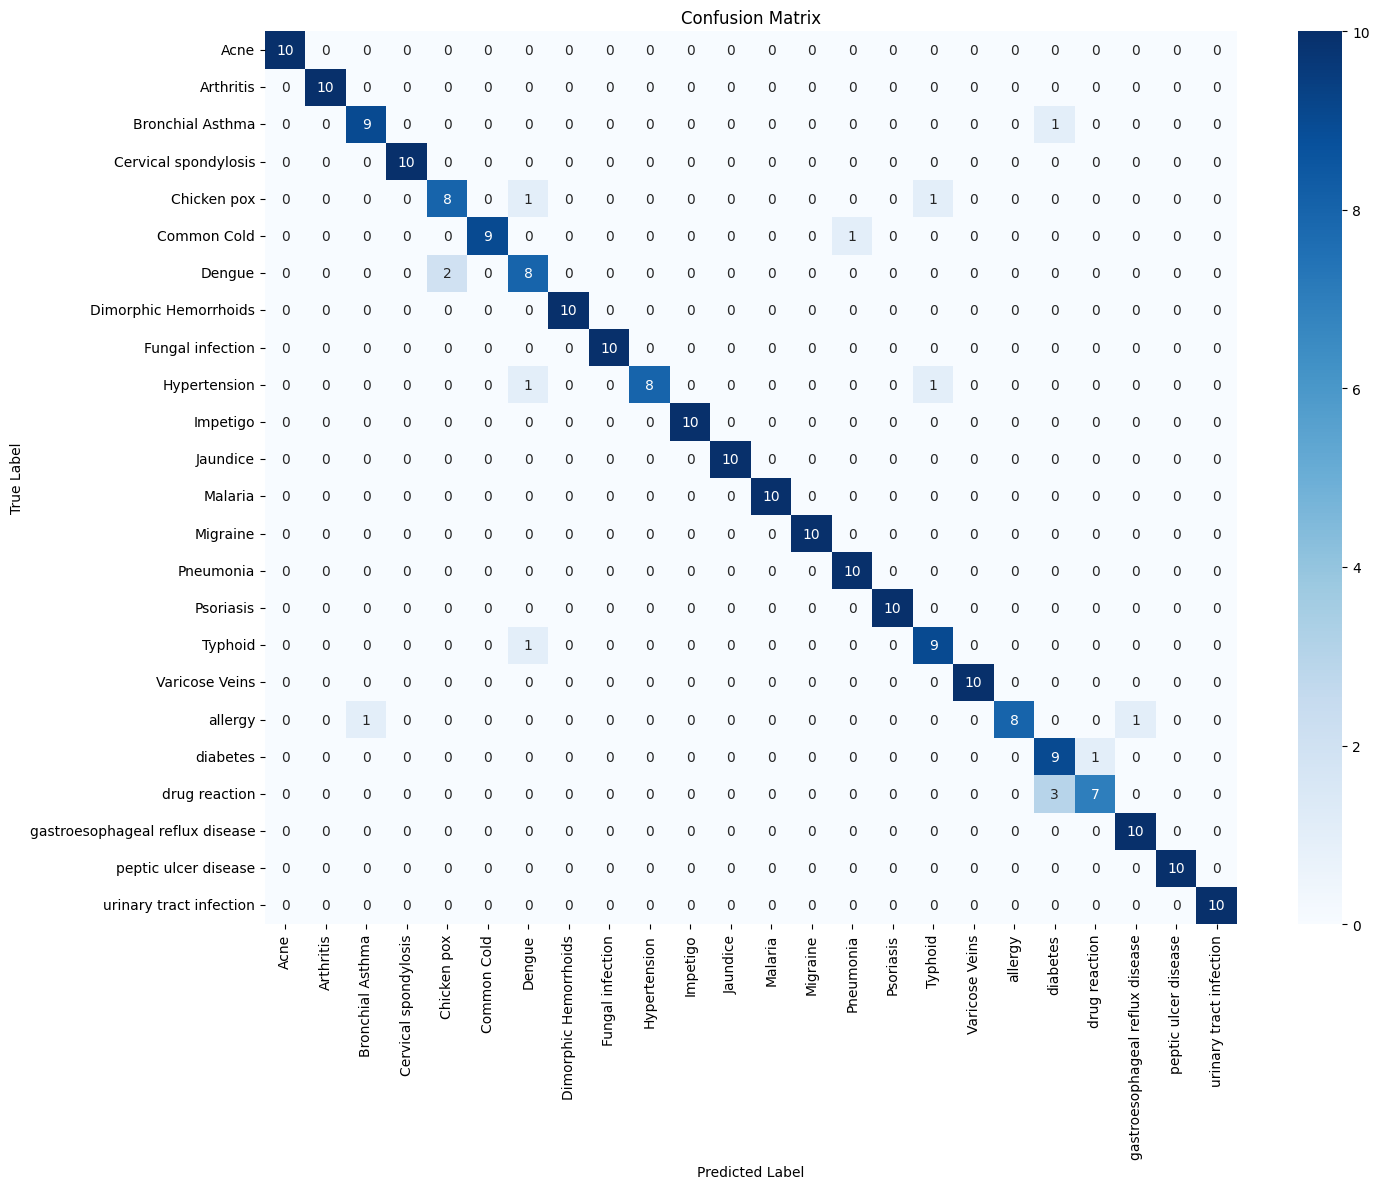

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
def predict_and_visualize_attention(text_input, model, vocab, label_encoder, max_len, device, preprocess_func):
    model.eval()

    # 1. Preprocess the input text
    cleaned_text = preprocess_func(text_input)
    print(f"Cleaned Text: {cleaned_text}")

    # 2. Numericalize the cleaned text
    numericalized_text = vocab.numericalize(cleaned_text)

    # 3. Pad/Truncate the numericalized text
    if len(numericalized_text) < max_len:
        padded_text = numericalized_text + [vocab.word2idx[vocab.pad_token]] * (max_len - len(numericalized_text))
    else:
        padded_text = numericalized_text[:max_len]

    # 4. Convert to PyTorch tensor
    input_tensor = torch.tensor(padded_text, dtype=torch.long).unsqueeze(0).to(device) # Add batch dimension

    # 5. Make a prediction and get attention weights
    with torch.no_grad():
        logits, attn_weights = model(input_tensor)

    # 6. Convert prediction to human-readable label
    predicted_label_idx = torch.argmax(logits, dim=1).item()
    predicted_label = label_encoder.inverse_transform([predicted_label_idx])[0]

    print(f"Predicted Disease: {predicted_label}")

    # 7. Visualize attention weights
    # Remove padding from attention weights for visualization
    # The attention weights correspond to the sequence length *before* padding if it's shorter than max_len
    # or the max_len if it's truncated.
    original_words = cleaned_text.split()
    effective_length = min(len(original_words), max_len)

    # Get attention weights for the first (and only) item in the batch
    # We take the weights corresponding to the actual words, not the padding
    attention_scores = attn_weights[0, :effective_length].cpu().numpy()

    # Get the words that actually received attention
    words_for_attention = original_words[:effective_length]

    # Create heatmap
    plt.figure(figsize=(max(8, len(words_for_attention) * 0.8), 3))
    sns.heatmap(attention_scores.reshape(1, -1), cmap='viridis', annot=True, fmt='.2f',
                xticklabels=words_for_attention, yticklabels=['Attention'])
    plt.title(f'Attention Weights for Predicted Disease: {predicted_label}')
    plt.xlabel('Words')
    plt.ylabel('Attention')
    plt.yticks(rotation=0)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    return predicted_label, attention_scores

In [ ]:
test_text = X_test[0]
test_label_encoded = y_test[0]
test_label = label_encoder.inverse_transform([test_label_encoded])[0]
print(f"Test Text: {test_text}")
print(f"True Label: {test_label}")

Test Text: ive experiencing chill feel really exhausted cough wont go away cough chest ache heart pounding disgusting brownish hue mucous im coming
True Label: Pneumonia


Cleaned Text: ive experiencing chill feel really exhausted cough wont go away cough chest ache heart pounding disgusting brownish hue mucous im coming
Predicted Disease: Pneumonia


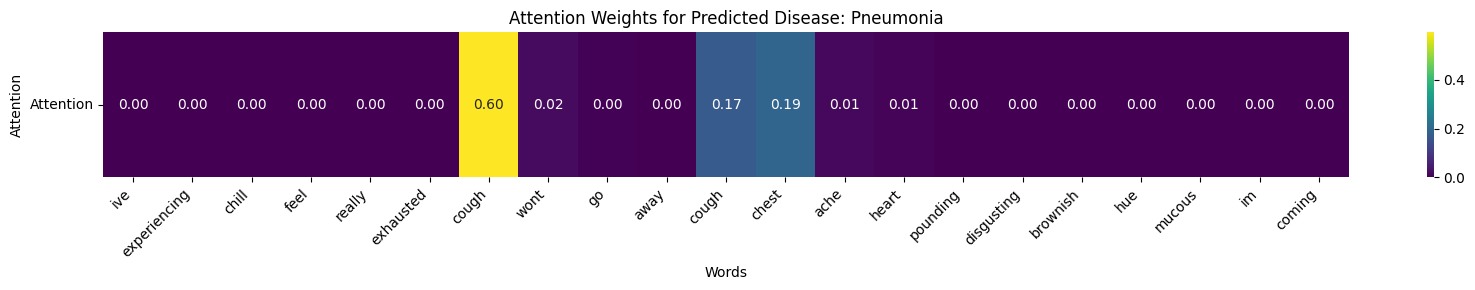

In [ ]:
predicted_label, attention_scores = predict_and_visualize_attention(test_text, model, vocab, label_encoder, max_len, device, preprocess_text)